In [19]:
import matplotlib.pyplot as plt

In [20]:
from pdm.data import load_cmapss, load_rul

train = load_cmapss("FD001", "train")
test = load_cmapss("FD001", "test")
rul = load_rul("FD001")

print(train.shape)
print(test.shape)
print(rul.shape)




(20631, 26)
(13096, 26)
(100, 2)


In [21]:
print(train.info())

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

In [22]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 13096 entries, 0 to 13095
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       13096 non-null  int64  
 1   cycle      13096 non-null  int64  
 2   setting_1  13096 non-null  float64
 3   setting_2  13096 non-null  float64
 4   setting_3  13096 non-null  float64
 5   sensor_1   13096 non-null  float64
 6   sensor_2   13096 non-null  float64
 7   sensor_3   13096 non-null  float64
 8   sensor_4   13096 non-null  float64
 9   sensor_5   13096 non-null  float64
 10  sensor_6   13096 non-null  float64
 11  sensor_7   13096 non-null  float64
 12  sensor_8   13096 non-null  float64
 13  sensor_9   13096 non-null  float64
 14  sensor_10  13096 non-null  float64
 15  sensor_11  13096 non-null  float64
 16  sensor_12  13096 non-null  float64
 17  sensor_13  13096 non-null  float64
 18  sensor_14  13096 non-null  float64
 19  sensor_15  13096 non-null  float64
 20  sensor_16  13096 

In [23]:
rul.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   unit      100 non-null    int64
 1   true_rul  100 non-null    int64
dtypes: int64(2)
memory usage: 1.7 KB


In [24]:
test.isnull().sum()

unit         0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

In [25]:
lifetimes = train.groupby("unit")["cycle"].max()
lifetimes

unit
1      192
2      287
3      179
4      189
5      269
      ... 
96     336
97     202
98     156
99     185
100    200
Name: cycle, Length: 100, dtype: int64

In [26]:
print('Minimum lifetime: ',lifetimes.min())
print('Maximum lifetime: ',lifetimes.max())
print('Mean lifetime: ',lifetimes.mean())

Minimum lifetime:  128
Maximum lifetime:  362
Mean lifetime:  206.31


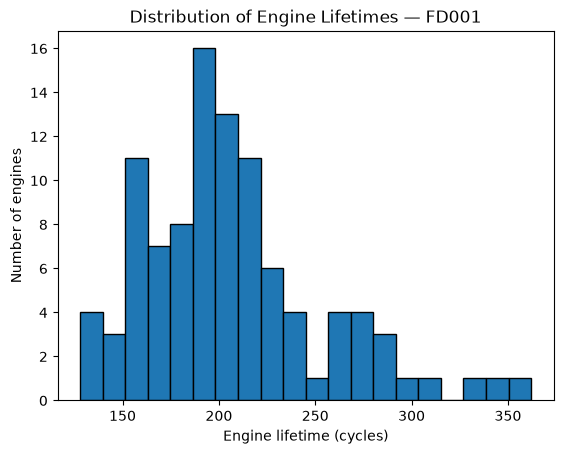

In [27]:
plt.hist(lifetimes,bins=20, edgecolor='black')

plt.xlabel("Engine lifetime (cycles)")
plt.ylabel("Number of engines")
plt.title("Distribution of Engine Lifetimes — FD001")

plt.show()

In [28]:
test_cycles = test.groupby("unit")["cycle"].max()
print(test_cycles)

print(test_cycles.agg(["min", "mean", "max"]))

unit
1       31
2       49
3      126
4      106
5       98
      ... 
96      97
97     134
98     121
99      97
100    198
Name: cycle, Length: 100, dtype: int64
min      31.00
mean    130.96
max     303.00
Name: cycle, dtype: float64


In [29]:
#qst 5: Do cycles start at 1 and increase by exactly 1 within each engine, with no gaps? => yes

check= train.groupby('unit')['cycle'].diff()
check

0        NaN
1        1.0
2        1.0
3        1.0
4        1.0
        ... 
20626    1.0
20627    1.0
20628    1.0
20629    1.0
20630    1.0
Name: cycle, Length: 20631, dtype: float64

In [30]:
#qst 6: constant/nearly constant columns
inspection = train.agg(["std", "nunique"]).T

inspection.sort_values("std")

,std,nunique
sensor_1,0.000000e+00,1.0
setting_3,0.000000e+00,1.0
sensor_10,0.000000e+00,1.0
sensor_18,0.000000e+00,1.0
sensor_19,0.000000e+00,1.0
sensor_16,3.469531e-18,1.0
sensor_5,5.329200e-15,1.0
setting_2,2.930621e-04,13.0
sensor_6,1.388985e-03,2.0
setting_1,2.187313e-03,158.0
